# Обучаемые функции

## 0. Условие

1. Выбрать табличный набор данных для задачи классификации:
    - В котором есть категориальные (не менее двух), и числовые признаки.
    - Необходимо предобработать его: заполнить пропуски, нормализовать и т.д.. Разбить на тренировочную и тестовую часть.
    - Даже если набор данных будет для бинарной классификации, реализация не должна специализироваться под это.
2. Реализовать стандартное обучаемое преобразование: умножение на матрицу, добавление вектора и применение функции активации.
    - Преобразование должно пересчитывать градиент для входа и параметров.
    - Должны поддерживаться не менее трёх функций активации (кроме `Sigmoid`, `Tanh`, `ReLU` и `Softmax`).
3. Реализовать модификацию матричного обучаемого преобразования, в котором скалярное произведение заменено на RBF ядро из SVM.
    - То есть, каждая координата вектора выхода получается как расстояние вектора входа с соответствующим вектором из матрицы параметров, а затем к нему применяется гауссова функция.
    - Для данного преобразования также необходимо реализовать пересчёт градиента.
4. Реализовать обёртку над преобразованиями, которая будет добавлять остаточную связь.
5. Реализовать функцию ошибки `SoftArgMaxCrossEntropy`, которая будет стабильно применять к вектору композицию `SoftArgMax` преобразования и логарифма, для вычисления перекрёстной энтропии с целевым вектором. Данная функция также должна вычислять градиент.
6. Реализовать любую модификацию адаптивного градиентного спуска.
7. Обучить несколько моделей с разным числом стандартных матричных преобразований. 
    - Для каждой модели подобрать хорошие гиперпараметры.
    - Проверить влияние остаточных связей, добавления слоёв батч-нормализации и дропаута.
    - На одном графике - соответствующие кривые обучения.
    - Замерить качество классификации (точность или F-меру) на тестовой части, построить зависимость от числа параметров и преобразований.
8. Повторить предыдущий шаг для модифицированного матричного преобразования.
9. Построить модель из комбинации обычных и модифицированных матричных преобразований. Повторить седьмой шаг для них.


In [1]:
# Python's own stuff
import sys
import math
import dataclasses
import time
import warnings
import itertools as itt
import operator as op
from pathlib import Path
from dataclasses import dataclass, field
from dataclasses import asdict as dc_asdict
from abc import ABC, abstractmethod
from contextlib import contextmanager

# Numpy/Scipy/other
import numpy as np
import scipy.special as sp_spec
import scipy.stats as sp_stats
import pickle
import sklearn as skl
from sklearn.model_selection import train_test_split

# Visualisation
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from ipywidgets import interactive, IntSlider, FloatSlider
from IPython.display import display, Markdown
from tqdm import tqdm

# Type checking
from typing import TYPE_CHECKING
from typing import override

if TYPE_CHECKING:
    from typing import Callable, Optional, Sequence
    from collections.abc import Iterable
    from numpy.typing import NDArray

# Config
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")

# Versions
print(f"Python={sys.version_info}")
print(f"numpy={np.__version__}  sklearn={skl.__version__} matplotlib={mpl.__version__}  pandas={pd.__version__}")


Python=sys.version_info(major=3, minor=14, micro=3, releaselevel='final', serial=0)
numpy=2.5.3  sklearn=1.9.1 matplotlib=3.11.2  pandas=3.0.6


## 1. Датасет

### Выбор


In [2]:
def fetch_ucirepo_cached(dataset_id: int, cache_dir: str | Path = "../../data_cache"):
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    cache_path = cache_dir / f"uci_dataset_{dataset_id}.pkl"

    if cache_path.is_file():
        with cache_path.open("rb") as f:
            return pickle.load(f)
    else:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=dataset_id)

        with cache_path.open("wb") as f:
            pickle.dump(dataset, f)

        return dataset

# fetch dataset 
DATASET_RAW = fetch_ucirepo_cached(891)

DATASET_RAW.data.features = DATASET_RAW.data.features.drop(columns=["ID"], errors="ignore")

# metadata 
print("Название:", DATASET_RAW.metadata["name"])
print("Описание:", DATASET_RAW.metadata["additional_info"]["summary"], sep="\n")
print("Задачи:", DATASET_RAW.metadata["tasks"])
print("Переменные:", DATASET_RAW.metadata["additional_info"]["variable_info"], sep="\n")

# variable information 
print(DATASET_RAW.variables)


Название: CDC Diabetes Health Indicators
Описание:
Dataset link: https://www.cdc.gov/brfss/annual_data/annual_2014.html
Задачи: ['Classification']
Переменные:
- Diabetes diagnosis
- Demographics (race, sex)
- Personal information (income, educations)
- Health history (drinking, smoking, mental health, physical health)
                    name     role     type      demographic  \
0                     ID       ID  Integer              NaN   
1        Diabetes_binary   Target   Binary              NaN   
2                 HighBP  Feature   Binary              NaN   
3               HighChol  Feature   Binary              NaN   
4              CholCheck  Feature   Binary              NaN   
5                    BMI  Feature  Integer              NaN   
6                 Smoker  Feature   Binary              NaN   
7                 Stroke  Feature   Binary              NaN   
8   HeartDiseaseorAttack  Feature   Binary              NaN   
9           PhysActivity  Feature   Binary        

### Предобработка

Теперь конвертируем в пригодный для модели вид и подготовим генерацию train/test с нормализацией.


In [3]:
def balanced_subsample(X, y, n_total=20_000, random_state=30):
    rng = np.random.default_rng(random_state)
    y = np.asarray(y)

    classes, counts = np.unique(y, return_counts=True)
    per_class = n_total // len(classes)

    per_class = min(per_class, counts.min())

    idx = []
    for c in classes:
        idx_c = np.flatnonzero(y == c)
        idx.append(rng.choice(idx_c, size=per_class, replace=False))

    idx = np.concatenate(idx)
    rng.shuffle(idx)
    return X.iloc[idx].reset_index(drop=True), y[idx]

def encode_features(dataset, n_total=20_000):
    from sklearn.preprocessing import OneHotEncoder, LabelEncoder

    X_raw = dataset.data.features
    y_raw = dataset.data.targets.iloc[:, 0]

    X_raw, y_raw = balanced_subsample(X_raw, y_raw, n_total=n_total)

    vars_df = dataset.variables.copy()

    if "name" not in vars_df.columns:
        vars_df = vars_df.reset_index()

    fm = vars_df.set_index("name")
    fm = fm[fm["role"] == "Feature"]

    numeric_cols = fm.loc[
        fm["type"].isin(["Integer", "Continuous"]), :
    ].index.tolist()

    categorical_cols = fm.loc[
        fm["type"].isin(["Categorical", "Binary"]), :
    ].index.tolist()

    target_encoder = LabelEncoder()
    y = target_encoder.fit_transform(y_raw)

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    X_cat = ohe.fit_transform(X_raw[categorical_cols])
    X_num = X_raw[numeric_cols].to_numpy(dtype=float)

    X = np.hstack([X_num, X_cat])
    feature_names = numeric_cols + list(ohe.get_feature_names_out(categorical_cols))

    meta = {
        "numeric_cols": numeric_cols,
        "categorical_cols": categorical_cols,
        "numeric_idx": list(range(len(numeric_cols))),
        "feature_names": feature_names,
        "encoder": ohe,
        "target_encoder": target_encoder,
    }
    return X, y, meta


In [4]:
DATASET_X, DATASET_y, DATASET_meta = encode_features(DATASET_RAW, n_total=5_000)
print(DATASET_X, DATASET_y, DATASET_meta, sep="\n")

DATASET_WIDTH = DATASET_X.shape[1]
DATASET_LENGTH = DATASET_y.shape[0]
DATASET_NUM_CLASSES = len(np.unique(DATASET_y))
print(DATASET_WIDTH, DATASET_LENGTH, DATASET_NUM_CLASSES)


[[29.  1.  0. ...  0.  1.  0.]
 [33.  3.  0. ...  1.  1.  0.]
 [29.  3.  2. ...  0.  0.  1.]
 ...
 [21.  4. 15. ...  0.  0.  1.]
 [25.  3.  5. ...  1.  1.  0.]
 [26.  4.  0. ...  0.  0.  1.]]
[1 1 1 ... 1 0 1]
{'numeric_cols': ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income'], 'categorical_cols': ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'], 'numeric_idx': [0, 1, 2, 3, 4, 5, 6], 'feature_names': ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income', 'HighBP_0', 'HighBP_1', 'HighChol_0', 'HighChol_1', 'CholCheck_0', 'CholCheck_1', 'Smoker_0', 'Smoker_1', 'Stroke_0', 'Stroke_1', 'HeartDiseaseorAttack_0', 'HeartDiseaseorAttack_1', 'PhysActivity_0', 'PhysActivity_1', 'Fruits_0', 'Fruits_1', 'Veggies_0', 'Veggies_1', 'HvyAlcoholConsump_0', 'HvyAlcoholConsump_1', 'AnyHealthcare_0', 'AnyHealthcare_1', 'NoDocbcC

In [5]:
def normalize_train_test(X_train, X_test, numeric_idx=None, *, scaler=None):
    if scaler is None:
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()

    X_train = np.asarray(X_train, dtype=float)
    X_test = np.asarray(X_test, dtype=float)

    if numeric_idx is None:
        return scaler.fit_transform(X_train), scaler.transform(X_test), scaler

    numeric_idx = np.asarray(numeric_idx, dtype=int)
    X_train_out = X_train.copy()
    X_test_out = X_test.copy()

    X_train_out[:, numeric_idx] = scaler.fit_transform(X_train[:, numeric_idx])
    X_test_out[:, numeric_idx] = scaler.transform(X_test[:, numeric_idx])

    return X_train_out, X_test_out, scaler

def make_train_test(test_size: float = 0.2, random_state: int = 30, normalize: bool = True):
    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        DATASET_X, DATASET_y, test_size=test_size, stratify=DATASET_y, random_state=random_state
    )

    if normalize:
        X_train_n, X_test_n, scaler = normalize_train_test(
            X_train, X_test, numeric_idx=DATASET_meta["numeric_idx"]
        )
        return (X_train_n, y_train), (X_test_n, y_test), scaler
    else:
        return (X_train, y_train), (X_test, y_test), None

print(*make_train_test(), sep="\n")


(array([[-1.239 ,  0.1537,  3.1598, ...,  0.    ,  0.    ,  1.    ],
       [-0.6869, -1.6436, -0.4549, ...,  0.    ,  0.    ,  1.    ],
       [-0.1349,  0.1537, -0.4549, ...,  0.    ,  1.    ,  0.    ],
       ...,
       [ 3.5914,  1.0523,  0.3885, ...,  0.    ,  1.    ,  0.    ],
       [ 0.4172,  1.0523,  3.1598, ...,  1.    ,  1.    ,  0.    ],
       [ 0.1412,  0.1537, -0.4549, ...,  1.    ,  1.    ,  0.    ]],
      shape=(4000, 35)), array([0, 0, 1, ..., 1, 1, 0], shape=(4000,)))
(array([[-0.2729, -0.745 , -0.4549, ...,  0.    ,  0.    ,  1.    ],
       [-1.239 , -0.745 , -0.4549, ...,  0.    ,  0.    ,  1.    ],
       [-0.8249, -0.745 , -0.4549, ...,  0.    ,  1.    ,  0.    ],
       ...,
       [-0.4109,  0.1537, -0.4549, ...,  0.    ,  1.    ,  0.    ],
       [-0.2729,  0.1537, -0.4549, ...,  1.    ,  0.    ,  1.    ],
       [-1.515 , -0.745 , -0.4549, ...,  0.    ,  1.    ,  0.    ]],
      shape=(1000, 35)), array([0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1

## 2. Стандартное обуч. преобразование

### Функции активации


In [6]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def softplus(x):
    return np.logaddexp(0.0, x)


def activation_swish(x):
    return x * sigmoid(x)


def activation_grad_swish(x):
    s = sigmoid(x)
    return s + x * s * (1.0 - s)


def activation_make_plu(alpha=1.0, beta=1.0):
    ae, be = np.exp(alpha), np.exp(beta)
    scale = be / (1.0 + abs(be))

    def f(x):
        return x + scale * np.sin(ae * x)

    def df(x):
        return 1.0 + scale * ae * np.cos(ae * x)

    return f, df


def activation_make_srelu(tl=-1.0, al=0.1, tr=1.0, ar=0.1):
    def f(x):
        return np.where(x <= tl, tl + al * (x - tl), np.where(x >= tr, tr + ar * (x - tr), x))

    def df(x):
        return np.where(x <= tl, al, np.where(x >= tr, ar, 1.0))

    return f, df


In [7]:
ACTIVATIONS = {
    "NONE": (lambda x: x, lambda x: np.ones_like(x)),
    "swish": (activation_swish, activation_grad_swish),
    "plu": activation_make_plu(alpha=1.8, beta=-1.8),                # alpha - частота sin, beta - сила sin
    "srelu": activation_make_srelu(tl=-1.0, al=0.1, tr=0.5, ar=0.2), # tl, tr - левая и правая границы; al, ar - множители за соотв. границами
}


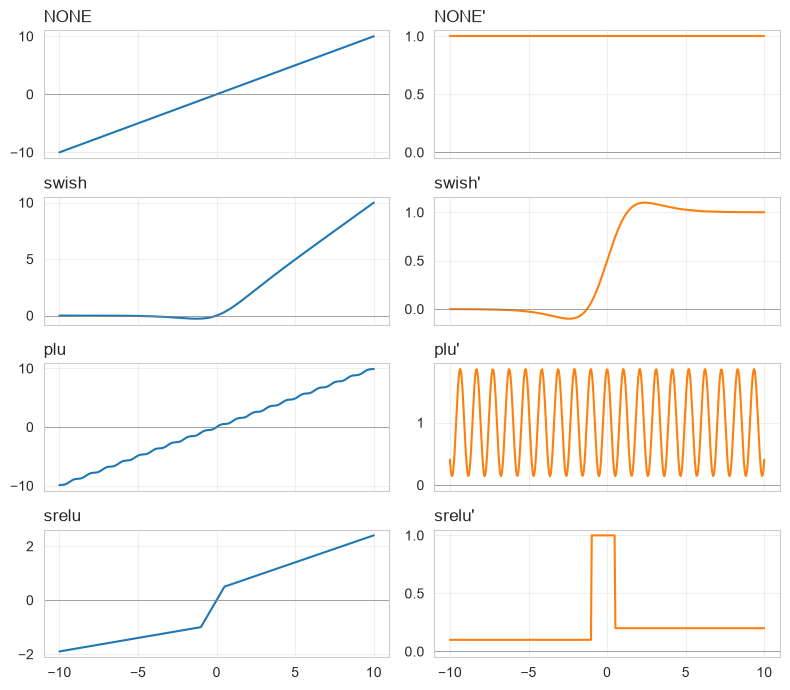

In [8]:
def demo_activations():
    x = np.linspace(-10, 10, 400)

    fig, ax = plt.subplots(len(ACTIVATIONS), 2, figsize=(8, 7), sharex=True)

    for row, (name, (f, df)) in zip(ax, ACTIVATIONS.items()):
        row[0].plot(x, f(x),  color="C0");  row[0].set_title(name, loc="left")
        row[1].plot(x, df(x), color="C1");  row[1].set_title(f"{name}'", loc="left")

        for a in row:
            a.axhline(0, color="gray", lw=0.5)
            a.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

demo_activations()


### Преобразование

Плюс тест через конечные разности.


In [9]:
class BaseTransform(ABC):
    # forward(x) -> y
    # backward(grad_output) -> (grad_x, grad_W, grad_b).

    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

    @abstractmethod
    def forward(self, x): ...

    @abstractmethod
    def backward(self, grad_output): ...

    @abstractmethod
    def parameters(self, prefix=""): ...

    @abstractmethod
    def gradients(self, prefix=""): ...

    def __call__(self, x):
        return self.forward(x)


In [10]:
class BaseTrainableTransform(BaseTransform):
    def __init__(self, in_features, out_features, activation="NONE"):
        assert activation in ACTIVATIONS

        super().__init__(in_features, out_features)

        self.activation = activation
        self._f, self._df = ACTIVATIONS[activation]

        self._cache: dict | None = None

    @override
    def parameters(self, prefix=""):
        return {prefix + "W": self.W, prefix + "b": self.b}

    @override
    def gradients(self, prefix=""):
        return {prefix + "W": self._cache["grad_W"], prefix + "b": self._cache["grad_b"]}

class TrainableTransform(BaseTrainableTransform):
    def __init__(self, in_features, out_features, activation="NONE", rng=None):
        super().__init__(in_features, out_features, activation)

        rng = rng if rng is not None else np.random.default_rng(30)
        scale = np.sqrt(2.0 / (in_features + out_features))

        self.W = rng.normal(0.0, scale, size=(out_features, in_features))
        self.b = np.zeros(out_features)

    @override
    def forward(self, x):
        x = np.asarray(x)
        z = x @ self.W.T + self.b

        self._cache = {"x": x, "z": z} # Reset

        return self._f(z)

    @override
    def backward(self, grad_output):
        x, z = self._cache["x"], self._cache["z"]

        dz = grad_output * self._df(z)
        dz2 = dz.reshape(-1, dz.shape[-1])
        x2  = x.reshape(-1, x.shape[-1])

        grad_W = dz2.T @ x2
        grad_b = dz2.sum(axis=0)
        grad_x = dz @ self.W

        self._cache["grad_W"], self._cache["grad_b"] = grad_W, grad_b # Update

        return grad_x, grad_W, grad_b


In [11]:
def check_gradients(ModelClass, x=None, g=None, eps=1e-6, **model_kwargs):
    rng = np.random.default_rng(30)

    x = rng.normal(size=(2, 5, 4)) if x is None else np.asarray(x)
    g = rng.normal(size=(2, 5, 3)) if g is None else np.asarray(g)
    in_features, out_features = x.shape[-1], g.shape[-1]

    for name in ACTIVATIONS.keys():
        model = ModelClass(in_features, out_features, activation=name, **model_kwargs)
        model.forward(x)
        gx, gW, gb = model.backward(g)
        W0, b0 = model.W.copy(), model.b.copy()

        # dL/dx — forward на сдвинутом x, W и b фиксированы
        ngx = np.zeros_like(x)
        for i in np.ndindex(x.shape):
            xp, xm = x.copy(), x.copy()
            xp[i] += eps; xm[i] -= eps
            ngx[i] = (np.sum(model.forward(xp) * g)
                      - np.sum(model.forward(xm) * g)) / (2 * eps)

        # dL/dW
        ngW = np.zeros_like(W0)
        for i in np.ndindex(W0.shape):
            model.W = W0.copy(); model.W[i] += eps
            Lp = float(np.sum(model.forward(x) * g))
            model.W = W0.copy(); model.W[i] -= eps
            Lm = float(np.sum(model.forward(x) * g))
            ngW[i] = (Lp - Lm) / (2 * eps)

        # dL/db
        model.W = W0
        ngb = np.zeros_like(b0)
        for i in np.ndindex(b0.shape):
            model.b = b0.copy(); model.b[i] += eps
            Lp = float(np.sum(model.forward(x) * g))
            model.b = b0.copy(); model.b[i] -= eps
            Lm = float(np.sum(model.forward(x) * g))
            ngb[i] = (Lp - Lm) / (2 * eps)

        model.W, model.b = W0, b0

        err = max(np.max(np.abs(ngx - gx)),
                  np.max(np.abs(ngW - gW)),
                  np.max(np.abs(ngb - gb)))
        print(f"{ModelClass.__name__} \t{name} \tmax|diff| = {err:.2e}")


In [12]:
check_gradients(TrainableTransform)


TrainableTransform 	NONE 	max|diff| = 1.34e-09
TrainableTransform 	swish 	max|diff| = 5.14e-10
TrainableTransform 	plu 	max|diff| = 1.82e-09
TrainableTransform 	srelu 	max|diff| = 8.22e-10


## 3. RBF обуч. преобразование

Тоже плюс тест через конечные разности.


In [13]:
class TrainableTransformRBF(BaseTrainableTransform):
    def __init__(self, in_features, out_features, activation="NONE", gamma=1.0, rng=None):
        super().__init__(in_features, out_features, activation)

        rng = rng if rng is not None else np.random.default_rng(30)

        self.W = rng.normal(0.0, 1.0, size=(out_features, in_features))
        self.b = np.zeros(out_features)

        self.gamma = np.full(out_features, float(gamma) / (2.0 * in_features))

    @override
    def forward(self, x):
        x = np.asarray(x)

        diff = x[..., None, :] - self.W
        sq = np.sum(diff * diff, axis=-1)
        s2 = np.exp(self.gamma)

        z = -sq / s2 + self.b
        k = np.exp(z - self.b)
        y = self._f(z)

        self._cache = {"diff": diff, "z": z, "sq": sq, "s2": s2} # Reset

        return y

    @override
    def backward(self, grad_output):
        diff, z, sq, s2 = (self._cache[x] for x in ["diff", "z", "sq", "s2"])
        
        dz = grad_output * self._df(z)
        c = -dz / s2
        c2 = c.reshape(-1, c.shape[-1])
        d2 = diff.reshape(-1, *diff.shape[-2:])

        grad_W = -2.0 * np.sum(c2[:, :, None] * d2, axis=0)
        grad_b = dz.reshape(-1, dz.shape[-1]).sum(axis=0)
        grad_x = 2.0 * np.sum(c[..., None] * diff, axis=-2)
        grad_gamma = np.sum(dz * sq / s2, axis=tuple(range(dz.ndim - 1)))

        self._cache["grad_W"], self._cache["grad_b"], self._cache["grad_gamma"] = grad_W, grad_b, grad_gamma # Update

        return grad_x, grad_W, grad_b

    @override
    def parameters(self, prefix=""):
        return {**super().parameters(prefix), prefix + "gamma": self.gamma}

    @override
    def gradients(self, prefix=""):
        return {**super().gradients(prefix), prefix + "gamma": self._cache["grad_gamma"]}


In [14]:
check_gradients(TrainableTransformRBF, gamma=0.1)
check_gradients(TrainableTransformRBF, gamma=1.0)
check_gradients(TrainableTransformRBF, gamma=10.0)


TrainableTransformRBF 	NONE 	max|diff| = 8.16e-09
TrainableTransformRBF 	swish 	max|diff| = 4.42e-11
TrainableTransformRBF 	plu 	max|diff| = 7.95e-09
TrainableTransformRBF 	srelu 	max|diff| = 1.21e-09
TrainableTransformRBF 	NONE 	max|diff| = 1.09e-08
TrainableTransformRBF 	swish 	max|diff| = 4.65e-11
TrainableTransformRBF 	plu 	max|diff| = 9.67e-09
TrainableTransformRBF 	srelu 	max|diff| = 1.26e-09
TrainableTransformRBF 	NONE 	max|diff| = 2.67e-09
TrainableTransformRBF 	swish 	max|diff| = 2.44e-10
TrainableTransformRBF 	plu 	max|diff| = 5.57e-09
TrainableTransformRBF 	srelu 	max|diff| = 7.84e-10


## 4. Обратная связь

И просто связь - соединяем преобразования в граф.


In [15]:
class Residual(BaseTransform):
    # y = x + inner(x) mребует in_features == out_features

    def __init__(self, inner: BaseTransform):
        assert inner.in_features == inner.out_features

        super().__init__(inner.in_features, inner.out_features)

        self.inner = inner

    @override
    def forward(self, x):
        return np.asarray(x) + self.inner.forward(x)

    @override
    def backward(self, grad_output):
        gx, gW, gb = self.inner.backward(grad_output)
        return grad_output + gx, gW, gb

    @override
    def parameters(self, prefix=""):
        return self.inner.parameters(f"{prefix}res.")

    @override
    def gradients(self, prefix=""):
        return self.inner.gradients(f"{prefix}res.")

class Sequential(BaseTransform):
    def __init__(self, *layers):
        assert len(layers) > 0

        super().__init__(layers[0].in_features, layers[-1].out_features)

        self.layers = list(layers)

    @override
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    @override
    def backward(self, grad_output):
        for layer in reversed(self.layers):
            grad_output, _, _ = layer.backward(grad_output)
        return grad_output, None, None

    @override
    def parameters(self, prefix=""):
        out = {}
        for i, layer in enumerate(self.layers):
            out.update(layer.parameters(f"{prefix}L{i}."))
        return out

    @override
    def gradients(self, prefix=""):
        out = {}
        for i, layer in enumerate(self.layers):
            out.update(layer.gradients(f"{prefix}L{i}."))
        return out


## 5. `SoftArgMaxCrossEntropy`

In [16]:
class SoftArgMaxCrossEntropy:
    def __init__(self):
        self._cache = None

    def forward(self, z, target):
        z = np.asarray(z)
        target = np.asarray(target)

        # log_softmax(z) = z - logsumexp(z), устойчиво относительно сдвига на max
        zmax = z.max(axis=-1, keepdims=True)
        logZ = zmax + np.log(np.sum(np.exp(z - zmax), axis=-1, keepdims=True))
        log_p = z - logZ

        loss = -np.sum(target * log_p, axis=-1)
        self._cache = (np.exp(log_p), target, loss.size)
        return loss.mean()

    def backward(self):
        p, target, n = self._cache
        return (p * target.sum(axis=-1, keepdims=True) - target) / n

    def __call__(self, z, target):
        return self.forward(z, target)


## 6. Градиентный спуск

Взял Adam, добавил W-модификацию с "угасанием" весов (она на синтетике дала чуть лучше ответ, так что оставляем).

Он технически был на методах оптимизации, но лично я его не делал, так как эта была последняя лаба и мне хватало 75 баллов с первых трёх :)

И можно начинать обучение - всё для сборки модели и обновления весов есть. 


In [17]:
class Adam:
    def __init__(self, params: dict, *, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = params

        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps

        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.t = 0

    def step(self, grads):
        self.t += 1

        for k, g in grads.items():
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * (g * g)

            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)

            self.params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

class AdamW(Adam):
    def __init__(self, *args, wd=1e-2, **kwargs):
        super().__init__(*args, **kwargs)

        self.wd = wd

    def step(self, grads):
        super().step(grads)

        for k in grads.keys():
            self.params[k] -= self.lr * self.wd * self.params[k]


In [18]:
IS_TRAINING = False

@contextmanager
def training_state(state: bool = True):
    global IS_TRAINING
    prev = IS_TRAINING

    IS_TRAINING = state

    try:
        yield
    finally:
        IS_TRAINING = prev


Ну, как видно, оно обучаемо:

In [19]:
def example_training():
    H, NUM_CLASSES = 9, 3
    rng = np.random.default_rng(30)

    # один слой -> два слоя внутри обратной связи -> один слой
    # Пробуем все 3 активации и оба типа слоёв
    model = Sequential(
        TrainableTransformRBF(H, H, activation="swish", rng=rng),
        Residual(Sequential(
            TrainableTransform(H, 1, activation="plu", rng=rng),
            TrainableTransform(1, H, activation="plu", rng=rng),
        )),
        TrainableTransform(H, 6, activation="srelu", rng=rng),
        TrainableTransform(6, NUM_CLASSES, rng=rng),
    )

    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=1e-2)

    # синтетика: класс = argmax по модулю от признаков + шума
    N = 512
    X = rng.normal(size=(N, H))
    y_idx = (X + 0.3 * rng.normal(size=(N, H))).argmax(axis=1) % NUM_CLASSES
    Y = np.eye(NUM_CLASSES)[y_idx]

    for epoch in range(501):
        with training_state():
            z = model.forward(X)
            L = loss_fn.forward(z, Y)
            model.backward(loss_fn.backward())
            opt.step(model.gradients())

        if epoch % 50 == 0:
            acc = (z.argmax(axis=-1) == y_idx).mean()
            print(f"epoch={epoch} \tloss={L:g} \tacc={acc:%}")

example_training()


epoch=0 	loss=1.09844 	acc=35.546875%
epoch=50 	loss=0.874098 	acc=55.664062%
epoch=100 	loss=0.680568 	acc=71.289062%
epoch=150 	loss=0.557954 	acc=77.343750%
epoch=200 	loss=0.518816 	acc=80.468750%
epoch=250 	loss=0.480477 	acc=81.835938%
epoch=300 	loss=0.440234 	acc=83.007812%
epoch=350 	loss=0.412877 	acc=84.375000%
epoch=400 	loss=0.393088 	acc=85.742188%
epoch=450 	loss=0.383981 	acc=86.328125%
epoch=500 	loss=0.365995 	acc=86.328125%


А вот RBF - не очень, а это я дал ему кратно больше и пареметров, и итераций, и вообще тут разделения train/test нет!

In [20]:
def example_training_rbf():
    H, NUM_CLASSES = 9, 3
    rng = np.random.default_rng(30)

    # один слой -> два слоя внутри обратной связи -> один слой
    # Пробуем все 3 активации
    model = Sequential(
        TrainableTransformRBF(H, H, activation="swish", rng=rng),
        Residual(Sequential(
            TrainableTransformRBF(H, 16, activation="srelu", gamma=10.0, rng=rng),
            TrainableTransformRBF(16, H, activation="srelu", gamma=10.0, rng=rng),
        )),
        TrainableTransformRBF(H, 6, activation="plu", rng=rng),
        TrainableTransformRBF(6, NUM_CLASSES, rng=rng),
    )

    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=1e-1)

    # синтетика: класс = argmax по модулю от признаков + шума
    N = 512
    X = rng.normal(size=(N, H))
    y_idx = (X + 0.3 * rng.normal(size=(N, H))).argmax(axis=1) % NUM_CLASSES
    Y = np.eye(NUM_CLASSES)[y_idx]

    for epoch in range(2_001):
        with training_state():
            z = model.forward(X)
            L = loss_fn.forward(z, Y)
            model.backward(loss_fn.backward())
            opt.step(model.gradients())

        if epoch % 50 == 0:
            acc = (z.argmax(axis=-1) == y_idx).mean()
            print(f"epoch={epoch} \tloss={L:g} \tacc={acc:%}")

example_training_rbf()


epoch=0 	loss=631.505 	acc=34.570312%
epoch=50 	loss=1.11165 	acc=34.375000%
epoch=100 	loss=1.10052 	acc=34.375000%
epoch=150 	loss=1.09755 	acc=34.375000%
epoch=200 	loss=1.09746 	acc=34.375000%
epoch=250 	loss=1.09717 	acc=34.375000%
epoch=300 	loss=1.09602 	acc=36.132812%
epoch=350 	loss=1.09249 	acc=37.304688%
epoch=400 	loss=1.08904 	acc=37.695312%
epoch=450 	loss=1.08374 	acc=37.695312%
epoch=500 	loss=1.07194 	acc=39.843750%
epoch=550 	loss=1.04589 	acc=44.335938%
epoch=600 	loss=0.993841 	acc=48.437500%
epoch=650 	loss=0.964405 	acc=50.781250%
epoch=700 	loss=0.940463 	acc=53.320312%
epoch=750 	loss=0.908044 	acc=54.687500%
epoch=800 	loss=0.862022 	acc=58.398438%
epoch=850 	loss=0.83149 	acc=63.867188%
epoch=900 	loss=0.793494 	acc=66.210938%
epoch=950 	loss=0.75385 	acc=70.507812%
epoch=1000 	loss=0.722077 	acc=72.460938%
epoch=1050 	loss=0.702232 	acc=73.632812%
epoch=1100 	loss=0.662467 	acc=73.242188%
epoch=1150 	loss=0.643238 	acc=74.804688%
epoch=1200 	loss=0.615594 	ac

## 7. Обучение линейных моделей

In [21]:
def train_base(model):
    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=1e-3)

    (X_train, y_train_idx), (X_test, y_test_idx), scaler = make_train_test(normalize=True)
    y_train = np.eye(DATASET_NUM_CLASSES)[y_train_idx]
    y_test = np.eye(DATASET_NUM_CLASSES)[y_test_idx]

    print(X_train.shape, y_train_idx.shape, X_test.shape, y_test_idx.shape)

    if True:
        z = model.forward(X_test)
        L = loss_fn.forward(z, y_test)
        acc = (z.argmax(axis=-1) == y_test_idx).mean()
        print(f"epoch=0 \tloss={L:g} \tacc={acc:%}")

    batch_size = 50
    for epoch_batch in range(10):
        for epoch in range(epoch_batch * batch_size, (epoch_batch + 1) * batch_size):
            with training_state():
                z = model.forward(X_train)
                L = loss_fn.forward(z, y_train)
                model.backward(loss_fn.backward())
                opt.step(model.gradients())

        train_loss = L
        train_acc = (z.argmax(axis=-1) == y_train_idx).mean()

        z = model.forward(X_test)
        L = loss_fn.forward(z, y_test)
        acc = (z.argmax(axis=-1) == y_test_idx).mean()
        print(f"epoch={(epoch_batch + 1) * batch_size} \tloss={L:.04f} \tacc={acc:%} \tt_loss={train_loss:.04f} \tt_acc={train_acc:%}")

def train():
    WIDTH, LENGTH = 32, 3

    train_base(Sequential(
        TrainableTransform(DATASET_WIDTH, WIDTH, activation="plu"),
        *[TrainableTransform(WIDTH, WIDTH, activation="swish") for _ in range(LENGTH)],
        TrainableTransform(WIDTH, DATASET_NUM_CLASSES),
    ))

train()


(4000, 35) (4000,) (1000, 35) (1000,)
epoch=0 	loss=0.706889 	acc=45.600000%
epoch=50 	loss=0.4990 	acc=75.600000% 	t_loss=0.5015 	t_acc=75.425000%
epoch=100 	loss=0.4962 	acc=75.700000% 	t_loss=0.4854 	t_acc=76.225000%
epoch=150 	loss=0.5036 	acc=76.300000% 	t_loss=0.4676 	t_acc=77.450000%
epoch=200 	loss=0.5283 	acc=74.300000% 	t_loss=0.4269 	t_acc=80.250000%
epoch=250 	loss=0.5777 	acc=73.000000% 	t_loss=0.3834 	t_acc=82.950000%
epoch=300 	loss=0.6330 	acc=70.900000% 	t_loss=0.3521 	t_acc=84.550000%
epoch=350 	loss=0.6924 	acc=72.200000% 	t_loss=0.3288 	t_acc=85.625000%
epoch=400 	loss=0.7550 	acc=70.900000% 	t_loss=0.3105 	t_acc=86.900000%
epoch=450 	loss=0.8125 	acc=70.200000% 	t_loss=0.2935 	t_acc=87.125000%
epoch=500 	loss=0.8713 	acc=70.200000% 	t_loss=0.2792 	t_acc=88.125000%


Ну такое себе, переобучается. Теперь добавим преобразований.

In [22]:
class Dropout(BaseTransform):
    def __init__(self, num_features, p=0.5, rng=None):
        assert 0.0 <= p < 1.0

        super().__init__(num_features, num_features)

        self.p = p
        self.rng = rng if rng is not None else np.random.default_rng(0)

        self._cache = {}

    @override
    def forward(self, x):
        x = np.asarray(x)

        if not IS_TRAINING or self.p == 0.0:
            return x

        keep = 1.0 - self.p
        mask = (self.rng.random(x.shape) < keep) / keep

        self._cache = {"mask": mask}

        return x * mask

    @override
    def backward(self, grad_output):
        mask = self._cache["mask"]
        return (grad_output if mask is None else grad_output * mask), None, None

    @override
    def parameters(self, prefix=""):
        return {}

    @override
    def gradients(self, prefix=""):
        return {}


In [23]:
class BatchNorm(BaseTransform):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__(num_features, num_features)

        self.eps, self.momentum = eps, momentum

        self.gamma = np.ones(num_features)
        self.beta = np.zeros(num_features)

        self.running_mean = np.zeros(num_features)
        self.running_var = np.ones(num_features)

        self._cache = {}

    def forward(self, x):
        x = np.asarray(x)

        if not IS_TRAINING:
            self._cache = {}
            inv_std = 1.0 / np.sqrt(self.running_var + self.eps)
            return (x - self.running_mean) * inv_std * self.gamma + self.beta

        x2 = x.reshape(-1, x.shape[-1])
        mu = x2.mean(axis=0)
        var = x2.var(axis=0)
        inv_std = 1.0 / np.sqrt(var + self.eps)
        xhat = (x2 - mu) * inv_std
        n = x2.shape[0]

        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mu
        self.running_var = ((1 - self.momentum) * self.running_var + self.momentum * var * n / (n - 1))

        self._cache = {"xhat": xhat, "inv_std": inv_std}

        return (xhat * self.gamma + self.beta).reshape(x.shape)

    def backward(self, grad_output):
        inv_std, xhat = self._cache["inv_std"], self._cache["xhat"]

        dy = grad_output.reshape(-1, grad_output.shape[-1])
        dnorm = dy * self.gamma
        dx = inv_std * (dnorm - dnorm.mean(axis=0) - xhat * (dnorm * xhat).mean(axis=0))

        grad_gamma = np.sum(dy * xhat, axis=0)
        grad_beta = dy.sum(axis=0)

        self._cache["grad_gamma"], self._cache["grad_beta"] = grad_gamma, grad_beta

        return dx.reshape(grad_output.shape), grad_gamma, grad_beta

    def parameters(self, prefix=""):
        return {prefix + "gamma": self.gamma, prefix + "beta": self.beta}

    def gradients(self, prefix=""):
        return {prefix + "gamma": self._cache["grad_gamma"], prefix + "beta": self._cache["grad_beta"]}


In [24]:
def train():
    WIDTH, LENGTH = 32, 3

    train_base(Sequential(
        TrainableTransform(DATASET_WIDTH, WIDTH, activation="plu"),
        *[TrainableTransform(WIDTH, WIDTH, activation="swish") for _ in range(LENGTH)],
        BatchNorm(WIDTH),
        Dropout(WIDTH, 0.125),
        TrainableTransform(WIDTH, DATASET_NUM_CLASSES),
    ))

train()


(4000, 35) (4000,) (1000, 35) (1000,)
epoch=0 	loss=0.706889 	acc=45.600000%
epoch=50 	loss=0.5027 	acc=76.600000% 	t_loss=0.5292 	t_acc=73.675000%
epoch=100 	loss=0.5004 	acc=75.400000% 	t_loss=0.5048 	t_acc=75.425000%
epoch=150 	loss=0.5098 	acc=74.500000% 	t_loss=0.4817 	t_acc=77.400000%
epoch=200 	loss=0.5442 	acc=73.300000% 	t_loss=0.4412 	t_acc=78.900000%
epoch=250 	loss=0.6227 	acc=71.100000% 	t_loss=0.3899 	t_acc=81.775000%
epoch=300 	loss=0.7265 	acc=69.700000% 	t_loss=0.3490 	t_acc=84.525000%
epoch=350 	loss=0.8196 	acc=67.300000% 	t_loss=0.3156 	t_acc=85.850000%
epoch=400 	loss=0.9349 	acc=68.100000% 	t_loss=0.2957 	t_acc=86.950000%
epoch=450 	loss=1.0245 	acc=67.400000% 	t_loss=0.3139 	t_acc=85.250000%
epoch=500 	loss=1.1096 	acc=66.700000% 	t_loss=0.2633 	t_acc=88.925000%


Теперь оно переобучается ещё быстрее, ура!

Дополнительные слои преобразований ускоряют обучение, это видно, но здесь оно играет против нас.

Поперебираем всякое теперь.


In [25]:
(X_train, y_train_idx), (X_test, y_test_idx), _ = make_train_test(normalize=True)
y_train = np.eye(DATASET_NUM_CLASSES)[y_train_idx]
y_test = np.eye(DATASET_NUM_CLASSES)[y_test_idx]

DATA = dict(X_tr=X_train, y_tr=y_train, y_tr_idx=y_train_idx, X_te=X_test,  y_te=y_test,  y_te_idx=y_test_idx)


In [26]:
def build_model_augm(width=32, length=2, activation="swish", RBF_start: bool=False, RBF_body: bool=False, RBF_end: bool=False):
    start = TrainableTransformRBF if RBF_start else TrainableTransform
    body = TrainableTransformRBF if RBF_body else TrainableTransform
    end = TrainableTransformRBF if RBF_end else TrainableTransform

    width2 = (width + DATASET_NUM_CLASSES + 1) // 2

    return Sequential(
        start(DATASET_WIDTH, width, activation="swish"),
        Residual(Sequential(
            *[body(width, width, activation=activation) for _ in range(length)]
        )),
        BatchNorm(width),
        Dropout(width, 0.125),
        end(width, width2, activation="plu"),
        end(width2, DATASET_NUM_CLASSES, activation="NONE"),
    )

def build_model_raw(width=32, length=2, activation="swish", RBF_start: bool=False, RBF_body: bool=False, RBF_end: bool=False):
    start = TrainableTransformRBF if RBF_start else TrainableTransform
    body = TrainableTransformRBF if RBF_body else TrainableTransform
    end = TrainableTransformRBF if RBF_end else TrainableTransform

    width2 = (width + DATASET_NUM_CLASSES + 1) // 2

    return Sequential(
        start(DATASET_WIDTH, width, activation="swish"),
        *[body(width, width, activation=activation) for _ in range(length)],
        end(width, width2, activation="plu"),
        end(width2, DATASET_NUM_CLASSES, activation="NONE"),
    )

def build_model(*args, augm: bool=False, **kwargs):
    return (build_model_augm if augm else build_model_raw)(*args, **kwargs)

def train_run(model, data, *, steps=300, lr=1e-3, wd=1e-2, log_every=10):
    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=lr, wd=wd)
    hist = {k: [] for k in ("step", "train_loss", "test_loss", "train_acc", "test_acc")}

    for step in range(1, steps + 1):
        with training_state():
            z = model.forward(data["X_tr"])
            L = loss_fn.forward(z, data["y_tr"])
            model.backward(loss_fn.backward())
            opt.step(model.gradients())

        if step == 1 or step % log_every == 0:
            hist["step"].append(step)
            hist["train_loss"].append(L)
            hist["train_acc"].append((z.argmax(-1) == data["y_tr_idx"]).mean())

            zt = model.forward(data["X_te"])
            hist["test_loss"].append(loss_fn.forward(zt, data["y_te"]))
            hist["test_acc"].append((zt.argmax(-1) == data["y_te_idx"]).mean())

    return hist


In [27]:
def plot_sweep(results):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for label, h in results.items():
        ax[0].plot(h["step"], h["test_loss"], label=label)
        ax[1].plot(h["step"], h["test_acc"],  label=label)
    ax[0].set(xlabel="step", ylabel="test loss", title="test loss")
    ax[1].set(xlabel="step", ylabel="test acc",  title="test acc")
    ax[1].legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()

def run_sweep(configs, *, steps=300, lr=1e-3, wd=1e-2):
    results = {}
    for label, p in tqdm(configs.items()):
        model = build_model(**p)
        results[label] = train_run(model, DATA, steps=steps, lr=lr, wd=wd)
    return results


Посмотрим на разные размеры сети:

Ну, в общем то, больше - лучше, с учвличением параметров сеть учится до чуть большего максимума, но явно ограничена архитектурно.


100%|██████████| 9/9 [00:50<00:00,  5.65s/it]


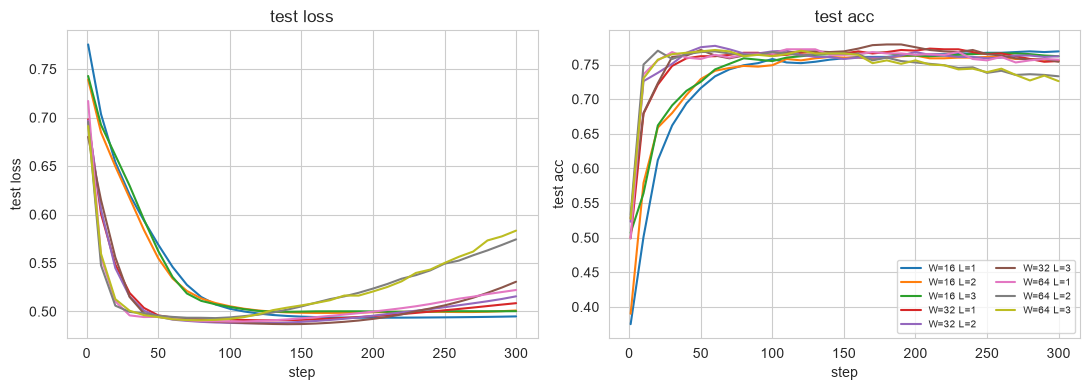

In [28]:
configs = {f"W={w} L={l}": dict(width=w, length=l) for w in (16, 32, 64) for l in (1, 2, 3)}
res = run_sweep(configs)
plot_sweep(res)


Теперь - на настройки оптимизатора:

Высокий `lr` трясёт и переобучается сильно, `wd` немного спасает от переобучения, но не сильно.

Лучше выбирать примерно `lr = 0.005` и `wd = 0.03`, оно и учится достаточно быстро, и потом довольно стабильно. От переобучения не спасёт, но от случайности инициализации защитит.


100%|██████████| 9/9 [00:29<00:00,  3.24s/it]


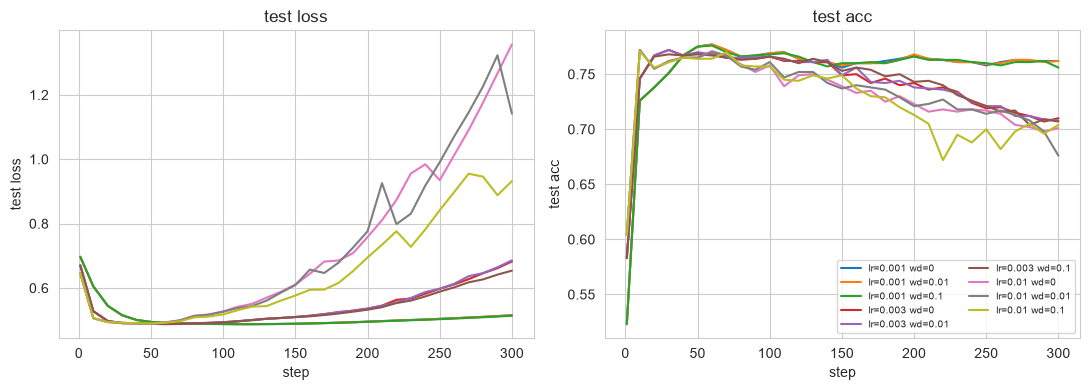

In [29]:
configs = {f"lr={lr:g} wd={wd:g}": dict(width=32, length=2, lr=lr, wd=wd)
           for lr in (1e-3, 3e-3, 1e-2) for wd in (0.0, 1e-2, 1e-1)}

res = {}
for label, p in tqdm(configs.items()):
    val = train_run(build_model(p["width"], p["length"]), DATA, steps=300, lr=p["lr"], wd=p["wd"])
    res[label] = val

plot_sweep(res)


Из функций активации самой хорошей оказалась swish, соревнуясь близко с srelu, а вот строго в конце - осциллирующая plu.

100%|██████████| 3/3 [00:09<00:00,  3.32s/it]


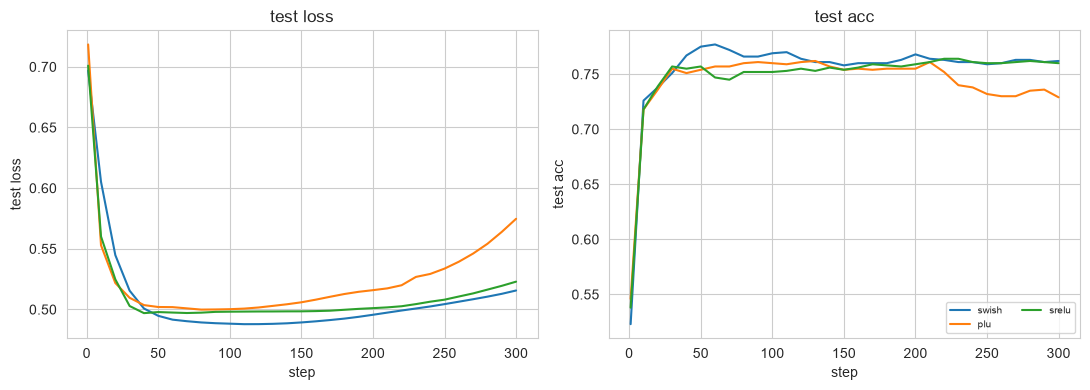

In [30]:
configs = {act: dict(width=32, length=2, activation=act) for act in ("swish", "plu", "srelu")}
res = run_sweep(configs)
plot_sweep(res)


А теперь проверим дополнительные преобразования.

На данном датасете обучение не ускоряется, всё в пределах погрешности, но зато ушло переобучение, как минимум на этой части. То есть положительно влияет.

100%|██████████| 2/2 [00:08<00:00,  4.45s/it]


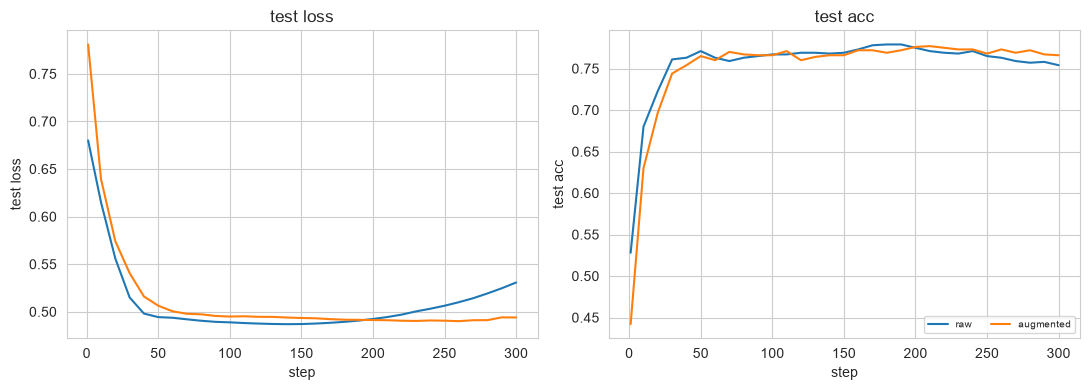

In [31]:
configs = {"augmented" if augm else "raw": dict(width=32, length=3, augm=augm) for augm in (False, True)}
res = run_sweep(configs)
plot_sweep(res)


## 8. Обучение RBF моделей

Нет.

Просто нет.

RBF - это ужас, он обучается кратно дольше и показывает околонулевую способность что-то предсказывать самостоятельно.

Я не представляю, какая магия нужна, чтобы оно заработало на хоть сколько-то реальном датасете. На CPU такого точно не дождаться.


100%|██████████| 2/2 [00:40<00:00, 20.01s/it]


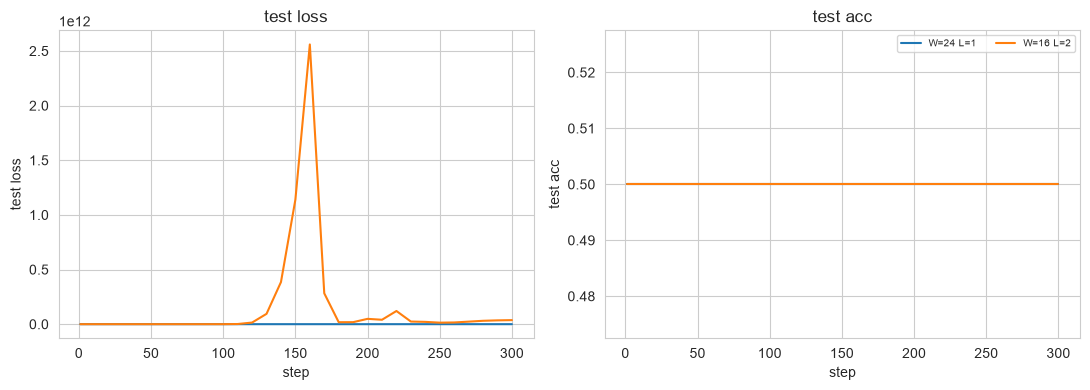

In [32]:
configs = {f"W={w} L={l}": dict(width=w, length=l, activation="srelu", augm=True, RBF_start=True, RBF_body=True, RBF_end=True) for w, l in ((24, 1), (16, 2))}
res = run_sweep(configs)
plot_sweep(res)

## 9. Обучение смешанных моделей

Ну, что тут сказать, добавление RBF приходится компенсировать понижением размеров, и такая сеть проигрывает по полной.

100%|██████████| 8/8 [01:53<00:00, 14.23s/it]


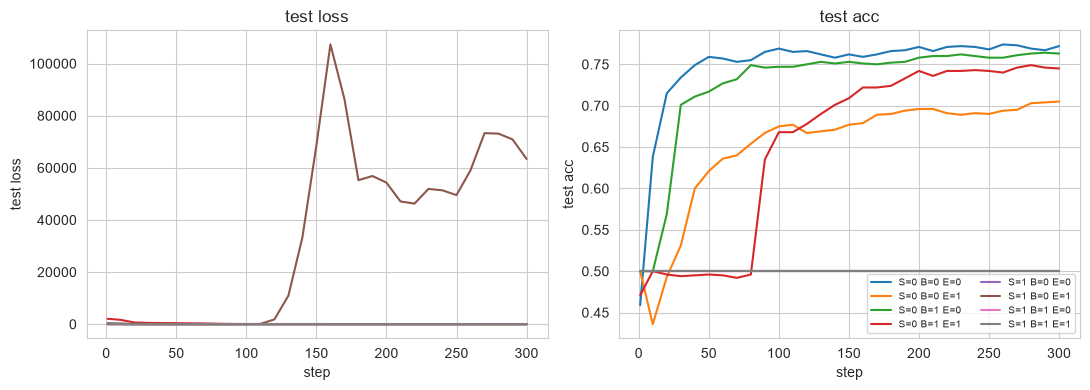

In [33]:
configs = {f"S={s} B={b} E={e}":
           dict(width=[32, 16, 32, 16][s + b + e], length=[2, 2, 1, 1][s + b + e], activation="srelu" if b else "swish", augm=True, RBF_start=bool(s), RBF_body=bool(b), RBF_end=bool(e))
           for s, b, e in itt.product((0, 1), repeat=3)}
res = run_sweep(configs)
plot_sweep(res)

Первый слой обязан быть линейным, иначе всё умирает, с ним выходит не прям совсем ужасно. Вон, RBF середина почти ничего не портит (~~потому что вокруг неё обратная связь...~~).

И вот теперь понятно, почему пункт 8 был обречён на провал.